# Getting started: define an arena and measure occupancy

**Estimated time**: 15-20 minutes

**Prerequisites**: None; basic NumPy is helpful.

Start with timestamped positions, represent the space the animal could visit,
and calculate how much recording time supports each bin. This notebook runs
independently with a small simulated recording and requires no downloads.

Run cells in order in a Python environment with `neurospatial` installed.
Keep `_style.py` beside this notebook; launching Jupyter from the repository
root or `examples/` both work. See the
[installation guide](https://edeno.github.io/neurospatial/getting-started/installation/)
for setup.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from shapely.geometry import box

from neurospatial import Environment
from neurospatial.ops.binning import regions_to_mask

_here = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
if not (_here / "_style.py").exists() and (_here / "examples" / "_style.py").exists():
    _here = _here / "examples"
if str(_here) not in sys.path:
    sys.path.insert(0, str(_here))
from _style import apply_style

apply_style(figsize=(11, 5))

## 1. Check the recording's coordinates and clock

Our arena is a known 60 × 60 cm square. The toy trajectory deliberately covers
only part of it. Reflected random steps generate this example; they are not a
fitted model of animal behavior. Positions have shape `(n_samples, 2)` and
timestamps are increasing seconds on one clock.

Setting `units="cm"` records the coordinate convention. It does not calibrate
camera pixels or rescale coordinates. Calibrate tracking before analysis.

In [2]:
rng = np.random.default_rng(101)
times = np.arange(2401, dtype=float) / 20.0
positions = np.empty((len(times), 2))
positions[0] = [25.0, 30.0]
lower, upper = np.array([5.0, 5.0]), np.array([45.0, 55.0])
span = upper - lower
for sample in range(1, len(times)):
    proposed = positions[sample - 1] + rng.normal(0.0, 1.2, size=2)
    positions[sample] = lower + np.abs((proposed - lower + span) % (2 * span) - span)

assert positions.shape == (len(times), 2)
assert np.isfinite(times).all() and np.isfinite(positions).all()
assert np.all(np.diff(times) > 0)
print(f"Tracking: {len(times):,} samples over {times[-1] - times[0]:.1f} s")
print(f"Median interval: {np.median(np.diff(times)):.3f} s")

Tracking: 2,401 samples over 120.0 s
Median interval: 0.050 s


## 2. Separate arena geometry from visited space

Use a known mask when the arena boundary is known. Here each `True` cell is
accessible space, including cells the animal never visited. Bin size is 5 cm;
grid edges therefore run from 0 to 60 cm in 5 cm steps.

`from_samples()` is useful when only tracking is available. Its default active
bins describe sampled space. A missing bin can mean unvisited space, so that
inferred boundary is not evidence of a physical wall.

Known arena: 144 accessible bins
Sample-inferred space: 66 visited bins


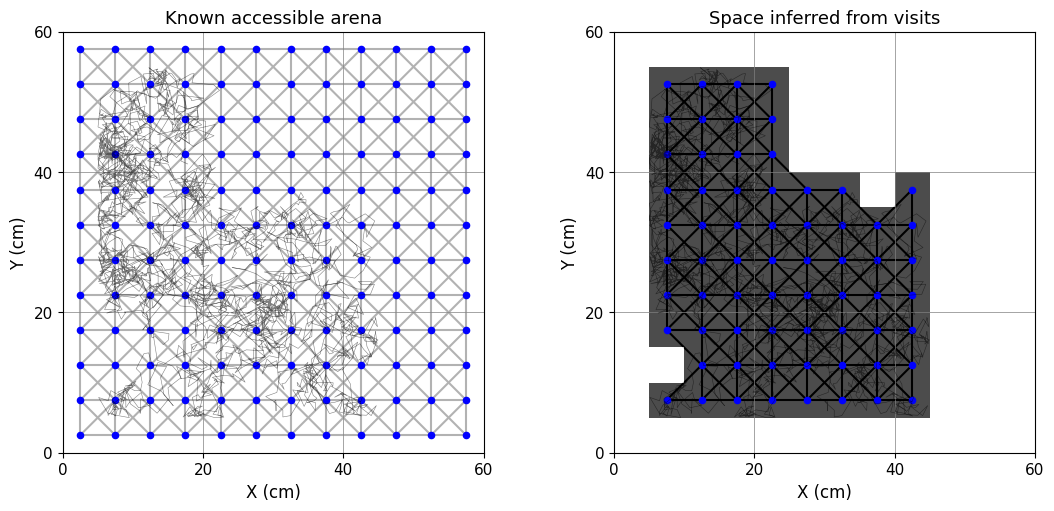

In [3]:
edges = np.arange(0.0, 60.0 + 5.0, 5.0)
env = Environment.from_grid_mask(
    active_mask=np.ones((12, 12), dtype=bool),
    grid_edges=(edges, edges),
    name="Known square arena",
)
env.units, env.frame = "cm", "arena"
sampled_env = Environment.from_samples(
    positions,
    bin_size=5.0,
    dimension_ranges=[(0.0, 60.0), (0.0, 60.0)],
    bin_count_threshold=1,
    name="Sampled space",
    units="cm",
    frame="arena",
)
print(f"Known arena: {env.n_bins} accessible bins")
print(f"Sample-inferred space: {sampled_env.n_bins} visited bins")

fig, axes = plt.subplots(1, 2, figsize=(11, 5), layout="constrained")
for ax, space, title in zip(
    axes, [env, sampled_env], ["Known accessible arena", "Space inferred from visits"]
):
    space.plot(ax=ax, show_connectivity=True)
    ax.plot(positions[:, 0], positions[:, 1], color="black", lw=0.4, alpha=0.5)
    ax.set(xlim=(0, 60), ylim=(0, 60), title=title, xlabel="X (cm)", ylabel="Y (cm)")
    ax.set_xticks([0, 20, 40, 60])
    ax.set_yticks([0, 20, 40, 60])
    ax.tick_params(bottom=True, left=True, labelbottom=True, labelleft=True)
    ax.set_aspect("equal")
plt.show()

## 3. Map positions to bins safely

`bin_at()` returns one integer per position and `-1` for an outside or missing
position. Filter that sentinel before indexing a field: NumPy interprets `-1`
as the last array element.

The unvisited upper-right corner belongs to the known arena. The same point
has no bin in the sample-inferred environment. Bin IDs belong to a particular
environment; do not reuse them after changing its geometry or resolution.

In [4]:
queries = np.array([[25.0, 30.0], [57.5, 57.5], [65.0, 10.0]])
known_bins = env.bin_at(queries)
sampled_bins = sampled_env.bin_at(queries)
for point, known_bin, sampled_bin in zip(queries, known_bins, sampled_bins):
    print(f"{point} cm -> known bin {known_bin:3d}; sampled-space bin {sampled_bin:3d}")

position_bins = env.bin_at(positions)
valid = position_bins >= 0
print(f"Tracking samples inside the known arena: {valid.mean():.1%}")
assert known_bins[1] >= 0 and sampled_bins[1] == -1
assert known_bins[2] == -1

[25. 30.] cm -> known bin  66; sampled-space bin  44
[57.5 57.5] cm -> known bin 143; sampled-space bin  -1
[65. 10.] cm -> known bin  -1; sampled-space bin  -1
Tracking samples inside the known arena: 100.0%


## 4. Measure occupancy in seconds

Occupancy accumulates intervals between timestamps, rather than counting
frames. With the default start-sample allocation, each valid interval is
assigned to its starting bin; the final sample adds no extra duration.
`max_gap=0.1` excludes any interval longer than 100 ms instead of assigning
missing recording time to one location. This example has no dropped frames.

Observed duration: 120.00 s
Visited bins: 66 / 144
Time in center bins: 24.85 s (20.7%)


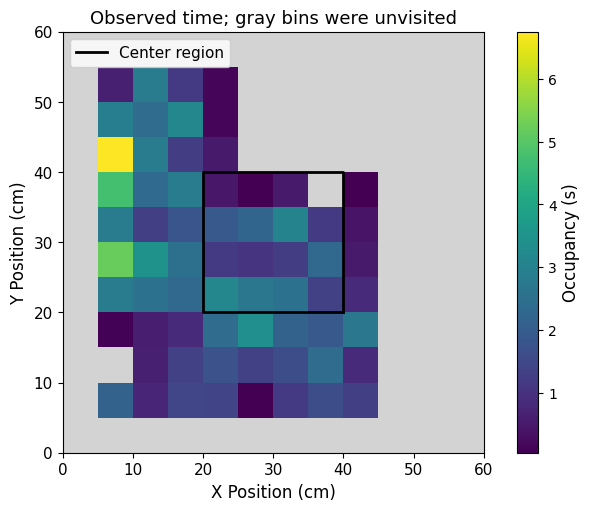

In [5]:
occupancy = env.occupancy(times, positions, max_gap=0.1)
observed = occupancy > 0
print(f"Observed duration: {occupancy.sum():.2f} s")
print(f"Visited bins: {observed.sum()} / {env.n_bins}")
assert np.isclose(occupancy.sum(), times[-1] - times[0])

# A named region is an analysis annotation; it does not change the arena graph.
env.regions.add("center", polygon=box(20.0, 20.0, 40.0, 40.0))
center_mask = regions_to_mask(env, "center")
center_time = occupancy[center_mask].sum()
print(f"Time in center bins: {center_time:.2f} s ({center_time / occupancy.sum():.1%})")

fig, ax = plt.subplots(figsize=(6, 5), layout="constrained")
env.plot_field(
    np.where(observed, occupancy, np.nan),
    ax=ax,
    cmap="viridis",
    nan_color="lightgray",
    colorbar_label="Occupancy (s)",
)
boundary_x, boundary_y = env.regions["center"].data.exterior.xy
ax.plot(boundary_x, boundary_y, color="black", lw=2, label="Center region")
ax.set_title("Observed time; gray bins were unvisited")
ax.legend(loc="upper left")
plt.show()

The region uses bin centers to decide membership, so its measured area is a
discretized approximation. Time fraction alone does not establish preference:
this simulation constrained the trajectory, and regions differ in area.
Gray means no observed occupancy here, rather than measured inactivity.

## 5. Choose a resolution the recording can support

Finer bins divide the same duration among more locations. Compare coverage and
dwell time before selecting a resolution; 5 cm is an example, not a universal
recommendation. Keep geometry fixed when making this comparison.

In [6]:
print("Bin width | Visited / arena bins | Median time per visited bin")
for bin_width in [2.5, 5.0, 10.0]:
    comparison_edges = np.arange(0.0, 60.0 + bin_width, bin_width)
    n_cells = len(comparison_edges) - 1
    comparison = Environment.from_grid_mask(
        active_mask=np.ones((n_cells, n_cells), dtype=bool),
        grid_edges=(comparison_edges, comparison_edges),
    )
    comparison.units, comparison.frame = "cm", "arena"
    dwell = comparison.occupancy(times, positions, max_gap=0.1)
    visited = dwell > 0
    print(
        f"{bin_width:5.1f} cm | {visited.sum():4d} / {comparison.n_bins:4d} bins"
        f"    | {np.median(dwell[visited]):.2f} s"
    )

Bin width | Visited / arena bins | Median time per visited bin
  2.5 cm |  234 /  576 bins    | 0.45 s
  5.0 cm |   66 /  144 bins    | 1.60 s
 10.0 cm |   26 /   36 bins    | 3.80 s


## Continue with your analysis

Use [02: spatial rate maps](02_spatial_rate_maps.ipynb) to combine spike times
with occupancy, or [03: trajectories and behavior](03_trajectories_and_behavior.ipynb)
to detect movement and track traversals. Each tutorial creates its own data.

For other geometry, see the
[environment guide](https://edeno.github.io/neurospatial/user-guide/environments/)
and [layout guide](https://edeno.github.io/neurospatial/user-guide/layout-engines/).
For camera calibration, rotation, and session alignment, use the
[alignment guide](https://edeno.github.io/neurospatial/user-guide/alignment/).
To connect separate arenas with explicit bridge assumptions, see
[composite environments](https://edeno.github.io/neurospatial/user-guide/composite-environments/).